# Model 5 - GAN vocoder
Run the setup cell first, then **Run all**. About 4-6 hours on a T4 (less on A100). Needs only notebook 00, so it can run while 02-04 are being prepared. Auto-resumes.

In [1]:
!pip install -q librosa soundfile num2words


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\INTEL\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import sys, torch
ROOT = r"C:\Users\INTEL\Downloads\voice_cloning_v2_1\voice_cloning_v2_1"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

GPU: NVIDIA GeForce RTX 4070


Vocoder training crops: 58094 | unseen-speaker validation crops: 64
[gan] starting fresh
[gan] epoch 1/100  g=40.8445  d=0.4784  mel=0.8406  val=1.5002  (153s)  * best
[gan] epoch 2/100  g=33.6368  d=0.1904  mel=0.6633  val=1.0842  (151s)  * best
[gan] epoch 3/100  g=30.9037  d=0.1267  mel=0.5962  val=0.7939  (151s)  * best
[gan] epoch 4/100  g=29.1374  d=0.0877  mel=0.5502  val=0.5839  (151s)  * best
[gan] epoch 5/100  g=27.6439  d=0.0628  mel=0.5112  val=0.4815  (153s)  * best
[gan] epoch 6/100  g=26.8712  d=0.0451  mel=0.4893  val=0.4324  (151s)  * best
[gan] epoch 7/100  g=26.2973  d=0.0430  mel=0.4733  val=0.4085  (152s)  * best
[gan] epoch 8/100  g=25.7744  d=0.0331  mel=0.4581  val=0.3938  (152s)  * best
[gan] epoch 9/100  g=25.4561  d=0.0296  mel=0.4481  val=0.3814  (152s)  * best
[gan] epoch 10/100  g=24.8394  d=0.0258  mel=0.4323  val=0.3718  (152s)  * best
[gan] epoch 11/100  g=24.7345  d=0.0236  mel=0.4276  val=0.3667  (151s)  * best
[gan] epoch 12/100  g=24.2972  d=0.0186 

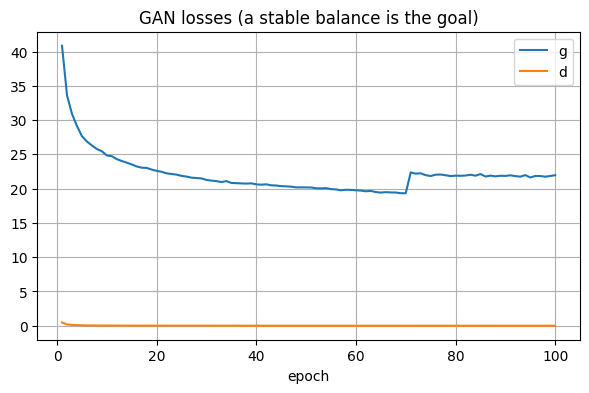

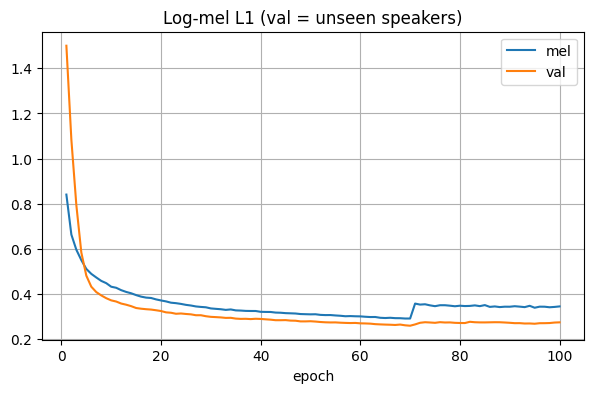

In [3]:
from vc_lib import train_gan
from vc_lib.common import plot_history

hist = train_gan.train(ROOT, epochs=100, steps_per_epoch=1000, batch_size=16)
plot_history(hist, ['g', 'd'], 'GAN losses (a stable balance is the goal)')
plot_history(hist, ['mel', 'val'], 'Log-mel L1 (val = unseen speakers)')

## Listen: real audio vs vocoder output (unseen speakers)

In [4]:
import torch
from IPython.display import Audio, display
from vc_lib import train_gan
from vc_lib.common import paths, tload, device, from_int16, SR
ho = tload(paths(ROOT)['gan_holdout']); G = train_gan.load_generator(ROOT)
for k in range(min(3, ho['mels'].size(0))):
    print(f'unseen speaker crop {k}')
    with torch.no_grad(): fake = G(ho['mels'][k].float()[None, None].to(device)).squeeze().cpu().numpy()
    display(Audio(from_int16(ho['wavs'][k]).numpy(), rate=SR)); display(Audio(fake, rate=SR))

unseen speaker crop 0


unseen speaker crop 1


unseen speaker crop 2
